# Six-target Heston inference with BayesFlow

This is the small offline workflow: simulate 10,000 training data sets and 100 validation data sets, fit one BayesFlow posterior estimator, then inspect recovery.

The six inferred quantities are five Heston parameters $(v_0, \kappa, \theta, \sigma_v, \rho)$ and the observation-noise multiplier $c$. The raw observations are the 54 option quotes from the PR task. Each quote is divided by its fixed half-spread, then the 54-vector is whitened using the full covariance estimated from training data only.

Use the `bfjax` environment and install this checkout once from the repository root with `python -m pip install -e ./tutorial -e ./lab` if it is not already installed. The notebook sets neither a random seed nor a Keras backend.

In [1]:
import json
from pathlib import Path

import bayesflow as bf
import matplotlib.pyplot as plt
import numpy as np
import sbi4finance

from sbi4finance.calibration.heston_spread import HestonSpreadPilot

INFO:bayesflow:Multiple Keras-compatible backends detected (JAX, PyTorch, TensorFlow). Defaulting to JAX.
To override, set the KERAS_BACKEND environment variable before importing bayesflow.
See: https://keras.io/getting_started/#configuring-your-backend
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO:bayesflow:Using backend 'jax'
E1110 16:11:15.293623 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.


In [2]:
LAB_ROOT = Path(sbi4finance.__file__).resolve().parents[2]
SPEC_PATH = (
    LAB_ROOT
    / "evidence/pilot-results/2026-11-09/heston-spread-baseline"
    / "noise-scale/recovery-inputs.json"
)
task = json.loads(SPEC_PATH.read_text())["task"]

model = HestonSpreadPilot(task["records"], infer_c=True, c_bounds=(0.5, 2.0))
model.validate_task(task["target"])

parameter_names = model.parameter_names
bounds = np.asarray(model.bounds)
half_spread = np.asarray(model.records["half_spread"])
list(zip(parameter_names, bounds.tolist(), strict=True))

[('initial_variance', [0.01, 0.16]),
 ('kappa', [0.1, 10.0]),
 ('theta', [0.01, 0.16]),
 ('vol_of_vol', [0.1, 3.0]),
 ('rho', [-0.95, -0.1]),
 ('c', [0.5, 2.0])]

In [3]:
rng = np.random.default_rng()

def prior():
    values = rng.uniform(bounds[:, 0], bounds[:, 1])
    return dict(zip(parameter_names, values, strict=True))

def observation_model(initial_variance, kappa, theta, vol_of_vol, rho, c):
    parameters = np.array([initial_variance, kappa, theta, vol_of_vol, rho, c])
    clean_prices = model.prices(parameters)
    quotes = clean_prices + c * half_spread * rng.standard_normal(half_spread.size)
    return {"observations": quotes / half_spread}

simulator = bf.make_simulator([prior, observation_model])

In [12]:
training_data = simulator.sample(10_000)
validation_data = simulator.sample(100)

{key: value.shape for key, value in training_data.items()}

{'initial_variance': (10000, 1),
 'kappa': (10000, 1),
 'theta': (10000, 1),
 'vol_of_vol': (10000, 1),
 'rho': (10000, 1),
 'c': (10000, 1),
 'observations': (10000, 54)}

In [13]:
# Covariance matrix
raw_training_conditions = training_data["observations"]
condition_mean = raw_training_conditions.mean(axis=0)
condition_covariance = np.cov(raw_training_conditions, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(condition_covariance)
eigenvalue_floor = eigenvalues[-1] * 1e-8
safe_eigenvalues = np.maximum(eigenvalues, eigenvalue_floor)
whitening_matrix = (eigenvectors / np.sqrt(safe_eigenvalues)) @ eigenvectors.T

def whiten(values):
    values = np.atleast_2d(values)
    return ((values - condition_mean) @ whitening_matrix)

training_data["observations"] = whiten(training_data["observations"])
validation_data["observations"] = whiten(validation_data["observations"])

{
    "condition_number_before": eigenvalues[-1] / eigenvalues[0],
    "condition_number_after": np.linalg.cond(
        np.cov(training_data["observations"], rowvar=False)
    ),
}

{'condition_number_before': np.float64(1051523.24628759),
 'condition_number_after': np.float64(1.0000000008352483)}

In [19]:
adapter = (
    bf.Adapter()
    .concatenate(parameter_names, into="inference_variables")
    .rename("observations", "inference_conditions")
)

workflow = bf.BasicWorkflow(
    adapter=adapter,
    inference_network=bf.networks.FlowMatching(subnet_kwargs={"widths": (128,)*3, "dropout": 0.1}),
    standardize="inference_variables",
)

In [20]:
history = workflow.fit_offline(
    data=training_data,
    validation_data=validation_data,
    epochs=200,
    batch_size=256,
)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/200


E1110 16:24:43.897924 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.


 1/40 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - loss: 4.1391

E1110 16:24:45.254149 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.


40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - loss: 3.6134 - val_loss: 2.8280
Epoch 2/200
 1/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.0328

E1110 16:24:45.860974 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.


40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.7070 - val_loss: 2.2518
Epoch 3/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.1413 - val_loss: 1.9896
Epoch 4/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.8370 - val_loss: 1.7492
Epoch 5/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.6623 - val_loss: 1.4251
Epoch 6/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.5204 - val_loss: 1.3380
Epoch 7/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.4078 - val_loss: 1.2342
Epoch 8/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.3284 - val_loss: 1.0734
Epoch 9/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.2502 - val_loss: 1.0431
Epoch 10/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1846 - val_loss: 1.1150
Epoch 11/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1473 - val_loss: 1.0006
Epoch 12/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0836 - val_loss: 1.0016
Epoch 13/200
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0426 - val_l

INFO:bayesflow:Training completed in 16.41 seconds.


In [21]:
samples = workflow.sample(conditions=validation_data, num_samples=300)

E1110 16:25:08.918559 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.
E1110 16:25:10.789274 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.
INFO:bayesflow:Sampling completed in 2.63 seconds.


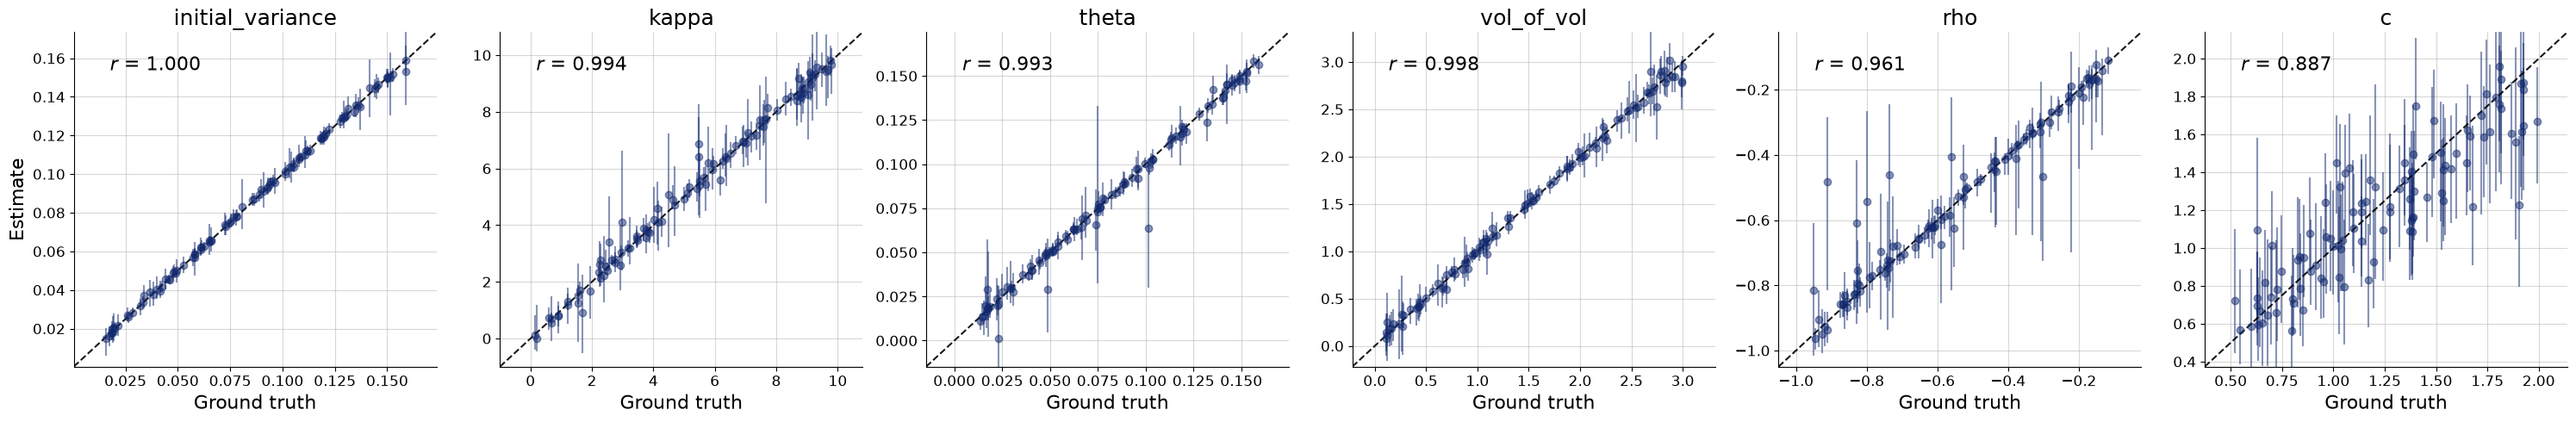

In [22]:
_ = bf.diagnostics.recovery(samples, validation_data)

## Does the estimator respond to $c$?

Hold the Heston parameters and one Gaussian noise direction fixed, then vary only $c$. This is a response diagnostic, not a calibration test. The dashed oracle line is the known-parameter conditional mode for this particular fixed noise draw.

In [ ]:
physical_parameters = np.array([
    validation_data[name][0, 0] for name in parameter_names[:-1]
])
clean_prices = model.prices(np.r_[physical_parameters, 1.0])
fixed_noise = rng.standard_normal(half_spread.size)
c_grid = np.linspace(0.5, 2.0, 9)

sweep_quotes = (
    clean_prices[None, :]
    + c_grid[:, None] * half_spread[None, :] * fixed_noise[None, :]
)
sweep_conditions = {"observations": whiten(sweep_quotes / half_spread)}
sweep_samples = workflow.sample(conditions=sweep_conditions, num_samples=1_000)
c_draws = np.asarray(sweep_samples["c"])[..., 0]
lower, median, upper = np.quantile(c_draws, [0.05, 0.5, 0.95], axis=1)
oracle_mode = np.clip(
    c_grid * np.sqrt(np.mean(fixed_noise**2)),
    bounds[-1, 0],
    bounds[-1, 1],
)

plt.figure(figsize=(6, 4))
plt.fill_between(c_grid, lower, upper, alpha=0.25, label="neural 90% interval")
plt.plot(c_grid, median, "o-", label="neural median")
plt.plot(c_grid, oracle_mode, "--", label=r"known-$\phi$ oracle mode")
plt.plot(c_grid, c_grid, color="black", alpha=0.35, label="identity")
plt.xlabel("generating $c$")
plt.ylabel("inferred $c$")
plt.legend()
plt.show()

E1110 16:26:48.451745 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.
E1110 16:26:48.517854 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor version. If using a binary install, upgrade your CuDNN library.  If building from sources, make sure the library loaded at runtime is compatible with the version specified during compile configuration.
E1110 16:26:48.823372 1513951 cuda_dnn.cc:435] Loaded runtime CuDNN library: 9.1.0 but source was compiled with: 9.8.0.  CuDNN library needs to have matching major version and equal or higher minor ve